# Musanga V4 — NB04 v4_007 | Final RGB Model A evaluation — 106 equal reference footprints

**Scientific unit:** Each spatially held-out reference footprint contributes **one equal-weight observation**, regardless of whether it was originally delineated as a circle or a plot. Their source type determines only which validated reference annotation is used for truth extraction in NB04; it does **not** change evaluation weights. Original 30 circles + 76 plots = **106 footprints**, all retained, including the four difficult MOS references.

**Primary outputs:** one pooled table (ALL + four forests); R², MAE, RMSE, bias, F1, IoU, precision, recall, RPD, RPIQ, Brier; one full-dataset scatterplot; site-specific scatterplots; combined cover strata; four largest errors. Statistics are **macro across reference footprints** (equal unit weights). Segmentation F1 and IoU are means of per-footprint metrics (not micro-pooled pixels). A short optional pixel-pooled segmentation summary is saved separately, but is not part of the main model-performance table.

**Preserves all predictions** from NB04, reusing the existing 106-unit CSV or `.npz` cache; no inference, no chip extraction, no GPU or retraining. Original files are read-only. Writes updated reports in `Outputs/v4/04_RGB_A_equal_footprints_v1/`.

**Important:** The earlier 50/50 circle–plot reweighting estimated a *different* quantity. Equal-footprint weighting gives every reference unit one vote and is now the primary scientific definition. The two formulations should not be conflated when comparing reported R² values.

**Reference caution:** Plot-background exhaustiveness is inherited provisionally from NB03; the four MOS prediction failures remain visible and in all metrics.

## 00 — Mount Drive and load saved evaluation (no inference)

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from google.colab import drive

if not Path('/content/drive/MyDrive').exists():
    drive.mount('/content/drive')

ROOTS=[Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final'),
       Path('/content/drive/MyDrive/Musanga/Final')]
BASE=next((r/'Outputs/v4/04_paired_rgb_heldout_v1' for r in ROOTS
           if (r/'Outputs/v4/04_paired_rgb_heldout_v1').exists()),None)
assert BASE is not None, 'NB04 saved output directory not found; check Drive mount'
OUT=BASE.parent/'04_RGB_A_equal_footprints_v1'
OUT.mkdir(parents=True,exist_ok=True)

# Prefer the precomputed CSV, but reconstruct from original saved per-unit files
# if the CSV is missing. Both paths are read-only to original outputs.
METRICS_CSV=BASE/'04_heldout_unit_metrics.csv'
if METRICS_CSV.is_file():
    df=pd.read_csv(METRICS_CSV)
    assert 'arm' in df.columns
    df=df[df.arm.eq('A')].copy()
    source='saved aggregate CSV'
else:
    files=sorted((BASE/'per_unit').glob('fold*_*.npz'))
    print('Existing per-unit evaluation cache:',len(files),'files')
    records=[]
    for f in files:
        with np.load(f,allow_pickle=False) as z:
            meta=json.loads(str(z['metadata'].item()))
            data=json.loads(str(z['A'].item()))
            records.append({**meta,**data,'arm':'A'})
    df=pd.DataFrame(records)
    source='saved per-unit NPZ cache'

assert len(df)==106, f'Expected 106 held-out units, got {len(df)}. Missing caches must be completed with earlier NB04; no inference is attempted here.'
df['unit_id']=df.unit_id.astype(str)
df['fold']=df.fold.astype(int)
assert df.unit_type.value_counts().to_dict()=={'plot':76,'circle':30}
assert not df.duplicated(['unit_type','unit_id']).any()
assert set(df.fold)=={0,1,2}
cols=['observed_cover_pp','predicted_cover_pp','n_pixels','F1','IoU','precision','recall',
      'brier','tp','fp','tn','fn']
assert set(cols).issubset(df.columns),set(cols)-set(df.columns)
assert df[['observed_cover_pp','predicted_cover_pp','n_pixels']].notna().all().all()
assert df.n_pixels.gt(0).all()
df['cover_error_pp']=df.predicted_cover_pp-df.observed_cover_pp
df['abs_cover_error_pp']=df.cover_error_pp.abs()
df.to_csv(OUT/'04_RGB_A_106_footprint_metrics.csv',index=False)
print('Loaded:',source,'| 106 equal footprints (30 circles + 76 plots) | folds:',sorted(df.fold.unique()))
print('No mosaics read, no inference, no retraining.')
print('Reporting folder:',OUT)

Mounted at /content/drive
Loaded: saved aggregate CSV | 106 equal footprints (30 circles + 76 plots) | folds: [np.int64(0), np.int64(1), np.int64(2)]
No mosaics read, no inference, no retraining.
Reporting folder: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/v4/04_RGB_A_equal_footprints_v1


## 01 — Main results: every held-out footprint counts equally

In [2]:
import numpy as np
import pandas as pd
from IPython.display import display

def macro_metrics(g):
    """Equal weight for each reference footprint, irrespective of shape or area."""
    obs=g.observed_cover_pp.to_numpy(dtype=float)
    pred=g.predicted_cover_pp.to_numpy(dtype=float)
    err=pred-obs
    n=len(g)
    mae=float(np.mean(np.abs(err)))
    rmse=float(np.sqrt(np.mean(err**2)))
    bias=float(np.mean(err))
    obs_var=float(np.mean((obs-obs.mean())**2))
    # RPD is sample SD / RMSE; RPIQ is unweighted quartile range / RMSE.
    sd=float(np.std(obs,ddof=1)) if n>1 else np.nan
    q1,q3=np.percentile(obs,[25,75]) if n else (np.nan,np.nan)
    return dict(
        n=n,
        R2=1-rmse**2/obs_var if obs_var>0 else np.nan,
        MAE_pp=mae,RMSE_pp=rmse,Bias_pp=bias,
        F1=float(g.F1.mean()),IoU=float(g.IoU.mean()),
        Precision=float(g.precision.mean()),Recall=float(g.recall.mean()),
        RPD=sd/rmse if rmse>0 else np.nan,
        RPIQ=(q3-q1)/rmse if rmse>0 else np.nan,
        Brier=float(g.brier.mean()))

assert len(df)==106 and not df.duplicated(['unit_type','unit_id']).any()
table=[]
for name,g in [('ALL',df),*list(df.groupby('site',sort=True))]:
    table.append(dict(Site=name,**macro_metrics(g)))
SUMMARY=pd.DataFrame(table)
SUMMARY.to_csv(OUT/'04_RGB_A_main_equal_footprint_statistics.csv',index=False)
print('FINAL RGB MODEL A — EQUAL REFERENCE FOOTPRINTS (all 106 retained)')
display(SUMMARY.round(3))
print('R² and cover errors are calculated across reference-footprint cover pairs.')
print('Mean F1/IoU/precision/recall are unweighted means of valid footprint scores.')

FINAL RGB MODEL A — EQUAL REFERENCE FOOTPRINTS (all 106 retained)


,Site,n,R2,MAE_pp,RMSE_pp,Bias_pp,F1,IoU,Precision,Recall,RPD,RPIQ,Brier
0,ALL,106,0.667,7.599,14.373,0.940,0.503,0.417,0.557,0.657,1.742,1.634,0.060
1,Baego,14,0.839,6.329,8.456,0.473,0.692,0.591,0.698,0.828,2.584,2.473,0.052
2,MOS,29,0.164,16.667,25.891,-3.424,0.630,0.531,0.725,0.701,1.113,1.895,0.153
3,Yangambi,48,-13.229,3.427,4.323,3.318,0.299,0.229,0.350,0.504,0.268,0.409,0.012
4,Yoko,15,0.939,4.604,6.112,2.199,0.596,0.514,0.637,0.708,4.193,5.499,0.041


R² and cover errors are calculated across reference-footprint cover pairs.
Mean F1/IoU/precision/recall are unweighted means of valid footprint scores.


## 02 — Supplementary pooled-pixel segmentation metrics (not the primary statistics)

In [3]:
# Optional supplementary segmentation statistics from saved confusion counts.
# Every evaluated pixel contributes equally here, unlike the main unit-macro table.
rows=[]
for name,g in [('ALL',df),*list(df.groupby('site',sort=True))]:
    tp,fp,fn,tn=(int(g[k].sum()) for k in ('tp','fp','fn','tn'))
    rows.append(dict(Site=name,n_units=len(g),n_pixels=int(g.n_pixels.sum()),
        F1_pooled=2*tp/(2*tp+fp+fn) if (2*tp+fp+fn)>0 else np.nan,
        IoU_pooled=tp/(tp+fp+fn) if (tp+fp+fn)>0 else np.nan,
        Precision_pooled=tp/(tp+fp) if (tp+fp)>0 else np.nan,
        Recall_pooled=tp/(tp+fn) if (tp+fn)>0 else np.nan))
MICRO=pd.DataFrame(rows)
MICRO.to_csv(OUT/'04_RGB_A_supplementary_pixel_pooled.csv',index=False)
print('Supplementary pixel-pooled segmentation performance (NOT footprint-weighted):')
display(MICRO.round(3))

Supplementary pixel-pooled segmentation performance (NOT footprint-weighted):


,Site,n_units,n_pixels,F1_pooled,IoU_pooled,Precision_pooled,Recall_pooled
0,ALL,106,295113667,0.674,0.508,0.621,0.736
1,Baego,14,14913829,0.813,0.684,0.836,0.791
2,MOS,29,11565795,0.717,0.558,0.722,0.711
3,Yangambi,48,217680707,0.475,0.311,0.393,0.601
4,Yoko,15,50953336,0.707,0.546,0.636,0.795


## 03 — All-footprint scatterplot, highlighting four largest errors

FOUR LARGEST ABSOLUTE COVER ERRORS — ALL RETAINED


,site,unit_type,unit_id,fold,observed_cover_pp,predicted_cover_pp,cover_error_pp,abs_cover_error_pp
48,MOS,plot,PK46_15Y1,2,74.31,2.94,-71.37,71.37
72,MOS,plot,PK49_40Y,2,78.24,7.63,-70.61,70.61
66,MOS,plot,PK46_30Y1,2,60.84,1.48,-59.36,59.36
46,MOS,circle,3,2,55.13,4.22,-50.91,50.91


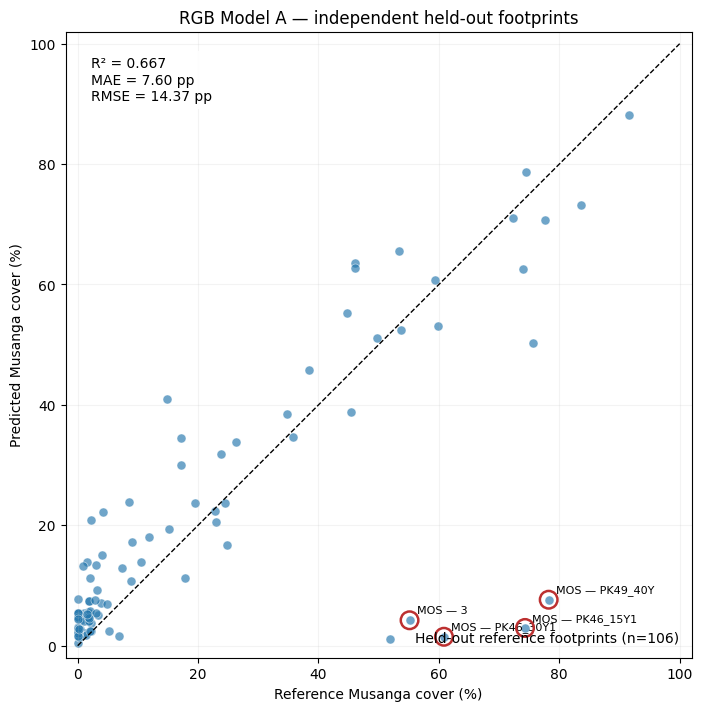

In [4]:
import matplotlib.pyplot as plt

top4=df.nlargest(4,'abs_cover_error_pp')[
    ['site','unit_type','unit_id','fold',
     'observed_cover_pp','predicted_cover_pp','cover_error_pp','abs_cover_error_pp']
].copy()
top4.to_csv(OUT/'04_RGB_A_four_largest_errors.csv',index=False)
print('FOUR LARGEST ABSOLUTE COVER ERRORS — ALL RETAINED')
display(top4.round(2))

fig,ax=plt.subplots(figsize=(7.5,7),constrained_layout=True)
ax.scatter(df.observed_cover_pp,df.predicted_cover_pp,s=42,
           color='#2477ad',alpha=.66,edgecolors='white',
           linewidths=.45,label=f'Held-out reference footprints (n={len(df)})')
ax.plot([0,100],[0,100],'k--',lw=1)
for z in top4.itertuples():
    ax.scatter(z.observed_cover_pp,z.predicted_cover_pp,s=160,
               facecolors='none',edgecolors='#bc3030',
               linewidths=1.8,zorder=5)
    ax.annotate(f'{z.site} — {z.unit_id}',
                (z.observed_cover_pp,z.predicted_cover_pp),
                xytext=(5,5),textcoords='offset points',fontsize=8)
overall=SUMMARY.iloc[0]
ax.text(.04,.96,f'R² = {overall.R2:.3f}\nMAE = {overall.MAE_pp:.2f} pp\nRMSE = {overall.RMSE_pp:.2f} pp',
        transform=ax.transAxes,ha='left',va='top',fontsize=10,
        bbox=dict(facecolor='white',edgecolor='none',alpha=.87))
ax.set(xlim=(-2,102),ylim=(-2,102),
       xlabel='Reference Musanga cover (%)',
       ylabel='Predicted Musanga cover (%)',
       title='RGB Model A — independent held-out footprints')
ax.set_aspect('equal',adjustable='box')
ax.grid(alpha=.15)
ax.legend(frameon=False,loc='lower right')
fig.savefig(OUT/'04_RGB_A_equal_footprint_scatter.png',dpi=230,bbox_inches='tight')
plt.show()

## 04 — Combined cover classes and per-forest scatterplots

COMBINED COVER STRATA — EQUAL FOOTPRINTS


,cover_stratum,n,F1,IoU,MAE_pp,RMSE_pp,Bias_pp
0,0–1%,34,0.134,0.109,3.225,3.877,3.225
1,1–5%,29,0.520,0.396,5.073,6.939,5.073
2,5–20%,14,0.571,0.442,8.549,10.823,6.485
3,20–40%,9,0.843,0.737,4.405,5.415,1.550
4,>40%,20,0.720,0.658,19.470,30.073,-13.096


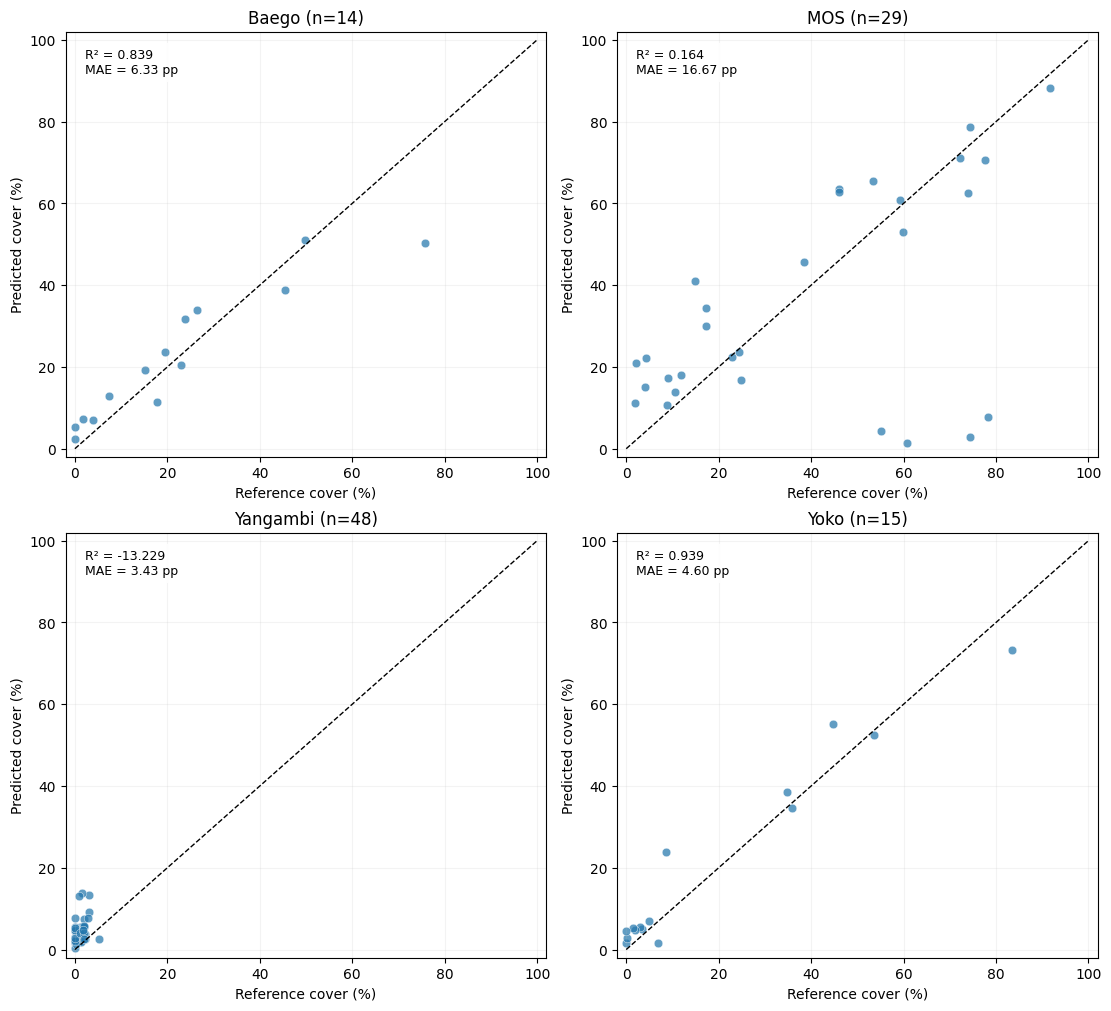

FINAL REPORT SAVED: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/v4/04_RGB_A_equal_footprints_v1


In [5]:
# Stratify by reference cover without separating circle and plot shapes.
bins=[-.001,1,5,20,40,100.001]
labels=['0–1%','1–5%','5–20%','20–40%','>40%']
df['cover_stratum']=pd.cut(df.observed_cover_pp,bins=bins,
                           labels=labels,include_lowest=True)
strata=[]
for label,g in df.groupby('cover_stratum',observed=True):
    strata.append(dict(cover_stratum=str(label),**macro_metrics(g)))
STRATA=pd.DataFrame(strata)
STRATA.to_csv(OUT/'04_RGB_A_combined_cover_strata.csv',index=False)
print('COMBINED COVER STRATA — EQUAL FOOTPRINTS')
display(STRATA[['cover_stratum','n','F1','IoU','MAE_pp','RMSE_pp','Bias_pp']].round(3))

# Forest panels: all footprints shown with the SAME symbol and weight.
sites=sorted(df.site.unique())
assert len(sites)==4
fig,axs=plt.subplots(2,2,figsize=(11,10),constrained_layout=True)
for ax,site in zip(axs.flat,sites):
    g=df[df.site.eq(site)]
    ax.scatter(g.observed_cover_pp,g.predicted_cover_pp,
               color='#2477ad',s=38,alpha=.72,edgecolors='white',linewidths=.4)
    ax.plot([0,100],[0,100],'k--',lw=1)
    m=macro_metrics(g)
    ax.text(.04,.96,f'R² = {m["R2"]:.3f}\nMAE = {m["MAE_pp"]:.2f} pp',
            transform=ax.transAxes,ha='left',va='top',fontsize=9,
            bbox=dict(facecolor='white',edgecolor='none',alpha=.85))
    ax.set(xlim=(-2,102),ylim=(-2,102),title=f'{site} (n={len(g)})',
           xlabel='Reference cover (%)',ylabel='Predicted cover (%)')
    ax.grid(alpha=.15)
fig.savefig(OUT/'04_RGB_A_equal_footprint_scatter_by_forest.png',
            dpi=220,bbox_inches='tight')
plt.show()

manifest=dict(
    notebook='NB04_v4_007_RGB_A_equal_footprint_final',
    model='A',n_reference_footprints=106,
    source_counts={'circle':30,'plot':76},
    primary_weighting='Each held-out reference footprint contributes equally',
    original_data_folder=str(BASE),report_folder=str(OUT),
    source=source,inference_recomputed=False,
    excluded_references=[],
    supplementary='Pixel-pooled classification metrics are secondary',
    exhaustive_plot_background_assumption='provisional, inherited from NB03'
)
(OUT/'04_RGB_A_equal_footprint_manifest.json').write_text(json.dumps(manifest,indent=2))
print('FINAL REPORT SAVED:',OUT)

## Interpretation and comparison with NB05

Every held-out reference footprint is treated as one observational unit, irrespective of its original circle/plot geometry, physical area or number of valid pixels. **No exclusions**: all four MOS cases remain. The same 106 cached NB04 predictions are used.

The main R², MAE, RMSE, bias, RPD, RPIQ and cover-stratum statistics are now **unweighted across footprints**, and F1/IoU are macro means across footprints. This differs intentionally from the previous 50/50 circle–plot weighting. The historical 106-unit RGB estimate under equal-footprint weighting was approximately R² **0.667**, F1 **0.503**, MAE **7.60 pp**; final exact values are recalculated from the CSV when this notebook runs.

**Important for NB05:** Its three-modality comparison should use the **same equal-footprint scheme** on the **identical RGB–DSM–MS-valid pixels** to be consistent with this NB04 definition. The full 106-footprint NB04 RGB scores and NB05 common-support RGB scores remain different estimands when MS coverage is incomplete.

Plot-background annotation exhaustiveness remains a provisional assumption, inherited from NB03. The four MOS failure cases should remain visible and described, not discarded.